<a href="https://colab.research.google.com/github/Cxjzzi/Deep-Learning-Labs/blob/main/Deep_Learning_Lab2_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Deep Learning Laboratories 2 & 3**
## **From Supervised Learning to a Shallow Neural Network**



## **5. Load the Required Libraries**

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
 mean_absolute_error,
 mean_squared_error,
 r2_score
)

## **6. Load and Inspect the Dataset**

In [10]:
df = pd.read_csv("/power_plant.csv")
print(df.head())
print(df.shape)
print(df.columns)
print(df.describe())
print(df.info())
print(df.isnull().sum())


      AT      V       AP     RH      PE
0  14.96  41.76  1024.07  73.17  463.26
1  25.18  62.96  1020.04  59.08  444.37
2   5.11  39.40  1012.16  92.14  488.56
3  20.86  57.32  1010.24  76.64  446.48
4  10.82  37.50  1009.23  96.62  473.90
(9568, 5)
Index(['AT', 'V', 'AP', 'RH', 'PE'], dtype='object')
                AT            V           AP           RH           PE
count  9568.000000  9568.000000  9568.000000  9568.000000  9568.000000
mean     19.651231    54.305804  1013.259078    73.308978   454.365009
std       7.452473    12.707893     5.938784    14.600269    17.066995
min       1.810000    25.360000   992.890000    25.560000   420.260000
25%      13.510000    41.740000  1009.100000    63.327500   439.750000
50%      20.345000    52.080000  1012.940000    74.975000   451.550000
75%      25.720000    66.540000  1017.260000    84.830000   468.430000
max      37.110000    81.560000  1033.300000   100.160000   495.760000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9568 ent

## **Questions:**

Q1. How many observations are in the dataset?

Q2. How many input variables are used?

Q3. Which variable are you trying to predict?

Q4. Is this a regression or classification problem? Explain why.

## **Answers:**

1. There are 9568 observations in this dataset.
2. There are 4 input variables: RH, AP, V and AT.
3. The variable I am trying to predict is power output (PE).
4. This is a regression problem because we are predicting a continuous, real-valued numerical target (net hourly electrical energy output, PE) rather than assigning observations to discrete classes or categories.

## **7. Visualize the Engineering Relationships**

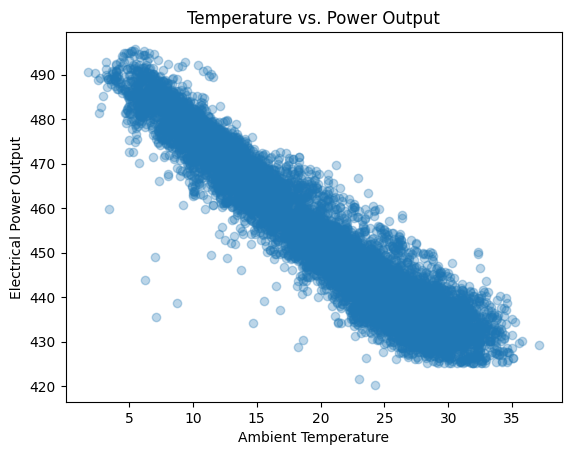

In [12]:
plt.scatter(df["AT"], df["PE"], alpha=0.3)
plt.xlabel("Ambient Temperature")
plt.ylabel("Electrical Power Output")
plt.title("Temperature vs. Power Output")
plt.show()


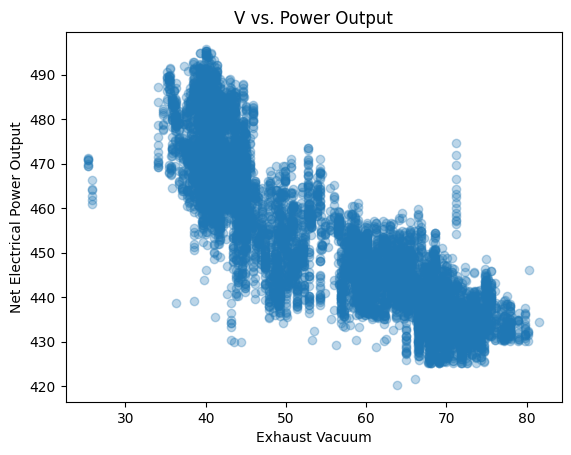

In [13]:
plt.scatter(df["V"], df["PE"], alpha=0.3)
plt.xlabel("Exhaust Vacuum")
plt.ylabel("Net Electrical Power Output")
plt.title("V vs. Power Output")
plt.show()


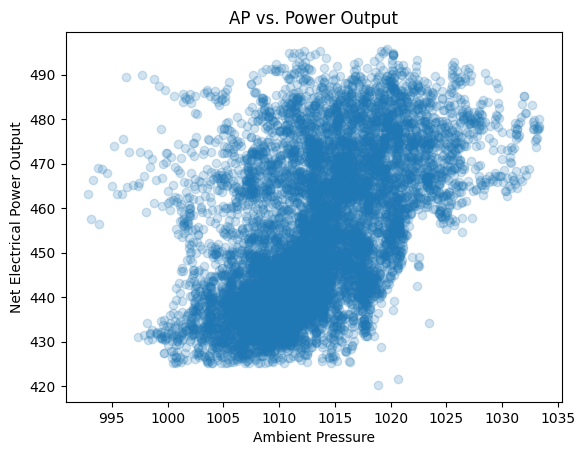

In [14]:
plt.scatter(df["AP"], df["PE"], alpha=0.2)
plt.xlabel("Ambient Pressure")
plt.ylabel("Net Electrical Power Output")
plt.title("AP vs. Power Output")
plt.show()

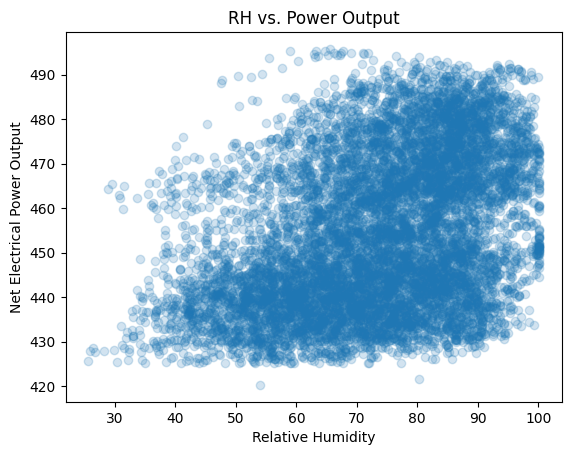

In [15]:
plt.scatter(df["RH"], df["PE"], alpha=0.2)
plt.xlabel("Relative Humidity")
plt.ylabel("Net Electrical Power Output")
plt.title("RH vs. Power Output")
plt.show()

## **Questions:**

Q5. Which variable appears to have the strongest visible relationship with power output?

Q6. Is the relationship approximately linear for every variable?

## **Answers:**

5. **Ambient Temperature (AT)** appears to have the strongest visible relationship with power output. The scatter plot shows a highly concentrated, tight downward diagonal trend, indicating a strong negative correlation.

6. **No, the relationship is not approximately linear for every variable.** While Ambient Temperature (AT) shows a clear and strong linear trend, Exhaust Vacuum (V) displays a more clustered, slightly curved relationship. Meanwhile, Ambient Pressure (AP) and Relative Humidity (RH) show weak, highly dispersed, and non-linear patterns.

## **8. Define Inputs and Target**


In [16]:
X = df[["AT", "V", "AP", "RH"]]
y = df["PE"]


## **9. Split the Data**


In [17]:
X_train, X_temp, y_train, y_temp = train_test_split(
 X, y, test_size=0.30, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
 X_temp, y_temp, test_size=0.50, random_state=42
)
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))


Training: 6697
Validation: 1435
Testing: 1436


## **10. Standardize the Inputs**

In [18]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

## **11. Build the Baseline Model**


In [19]:
baseline = LinearRegression()
baseline.fit(X_train_scaled, y_train)

LinearRegression()

## **12. Make Validation Predictions**

In [20]:
y_val_pred = baseline.predict(X_val_scaled)
comparison = pd.DataFrame({
 "Actual": y_val.values[:10],
 "Predicted": y_val_pred[:10]
})
print(comparison)


   Actual   Predicted
0  440.74  435.036365
1  432.09  433.789650
2  486.14  479.102298
3  442.75  439.039845
4  437.61  433.180482
5  481.77  476.246414
6  437.41  436.327719
7  465.95  466.500630
8  439.18  444.786069
9  438.42  438.915509


## Question:

Q7. Are the predicted values reasonably close to the actual values?

## Answer:

7. **Yes, the predicted values are reasonably close to the actual values.** The sample comparison shows predictions tracking within a few units of the true power output (e.g., 440.74 actual vs. 435.04 predicted).

## **13. Evaluate the Regression Model**

In [21]:
mae = mean_absolute_error(y_val, y_val_pred)
rmse = np.sqrt(
 mean_squared_error(y_val, y_val_pred)
)
r2 = r2_score(y_val, y_val_pred)
print("MAE :", mae)
print("RMSE:", rmse)
print("R^2 :", r2)

MAE : 3.645222450684648
RMSE: 4.562690287171953
R^2 : 0.930078295626855


## **14. Plot Actual vs. Predicted Values**

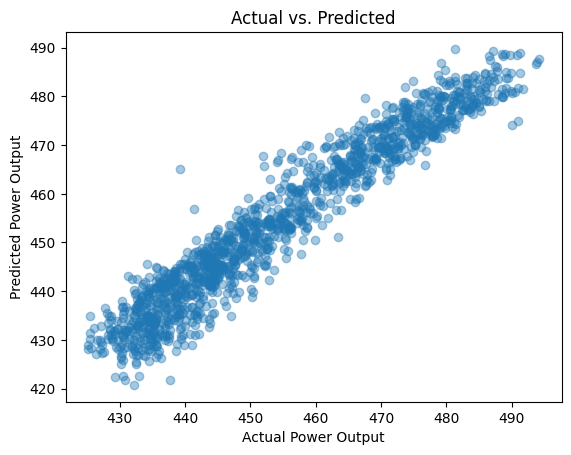

In [22]:
plt.scatter(y_val, y_val_pred, alpha=0.4)
plt.xlabel("Actual Power Output")
plt.ylabel("Predicted Power Output")
plt.title("Actual vs. Predicted")
plt.show()


## **15. Examine the Prediction Errors**


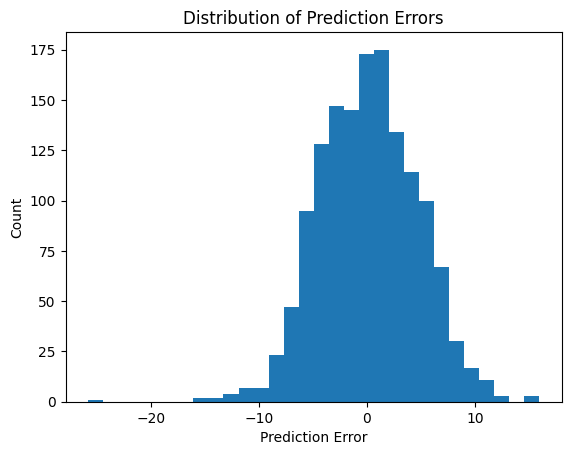

In [23]:
residuals = y_val.values - y_val_pred
plt.hist(residuals, bins=30)
plt.xlabel("Prediction Error")
plt.ylabel("Count")
plt.title("Distribution of Prediction Errors")
plt.show()



## **Questions**

Q8. Are the errors approximately centered around zero?

Q9. Are there any unusually large errors?

## **Answers**

8. **Yes, the errors are approximately centered around zero.** The histogram displays a clear, symmetric, bell-shaped distribution peak between -2 and +2, indicating that the model's predictions are unbiased.

9. **Yes, there are a few unusually large errors.** While the vast majority of errors fall within a tight range of ±10 MW, there are a tiny handful of outliers in the negative tail, with one notable prediction error extending past -25 MW.


# **16. Engineering Interpretation**

## **Question**

Q10. Would an average prediction error of approximately 4 MW be acceptable for every power-plant application?
Explain briefly.


## **Answer**

10. No, an average prediction error of approximately 4 MW would not be acceptable for every power-plant application. While a 4 MW error is highly accurate and negligible for massive, utility-scale base-load power plants producing several hundred megawatts, it could represent an unacceptably high percentage of total output for smaller, localized peaking plants, micro-grids, or facilities operating under strict, high-precision supply contracts.


## ***Part II - Lab 3: Shallow Neural Network***


## **19. Import PyTorch and Convert the Data**


In [24]:
import torch
import torch.nn as nn
torch.manual_seed(42)
X_train_t = torch.tensor(
 X_train_scaled, dtype=torch.float32
)
y_train_t = torch.tensor(
 y_train.values, dtype=torch.float32
).reshape(-1, 1)
X_val_t = torch.tensor(
 X_val_scaled, dtype=torch.float32
)
y_val_t = torch.tensor(
 y_val.values, dtype=torch.float32
).reshape(-1, 1)

## **20. Define the Shallow Neural Network**


In [25]:
model = nn.Sequential(
 nn.Linear(4, 16),
 nn.ReLU(),
 nn.Linear(16, 1)
)
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)


## **Question**

Q11: What would happen if the ReLU activation were removed and only linear layers remained?

## **Answer:**

11. The model would collapse into a single linear regression model. Without the non-linear ReLU activation, any combination of successive linear layers mathematically simplifies to a single linear transformation, preventing the network from learning the non-linear relationships present in the dataset.

## **21. Define the Loss Function and Optimizer**

In [26]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
 model.parameters(),
 lr=0.01
)


## **22. Train the Network**

In [27]:
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
    prediction,
    y_train_t
 )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
      val_prediction,
      y_val_t
 )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
  if epoch % 50 == 0:
    print(epoch, loss.item(), val_loss.item())

0 206681.390625 206856.09375
50 199569.890625 199364.59375
100 169719.546875 168368.375
150 119554.4296875 117248.3359375
200 70782.4765625 68474.8359375
250 39994.0390625 38540.41015625


## **23. Plot the Learning Curves**

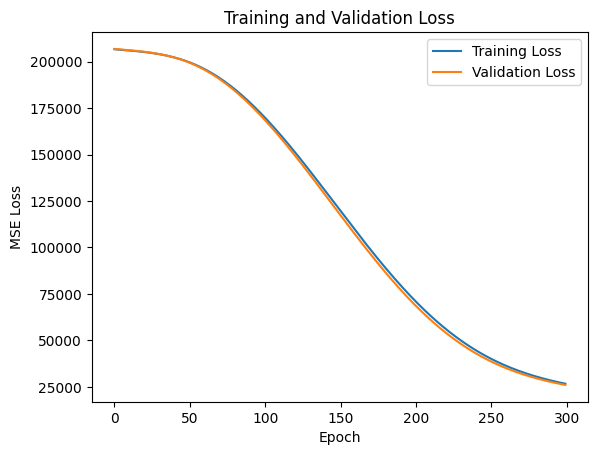

In [28]:
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

## **Questions**

Q12. What happened to the training loss as training progressed?

Q13. What happened to the validation loss?

Q14. Did the two curves behave similarly?


## **Answers**

12. The training loss steadily decreased as training progressed, dropping from an initial MSE of over 206,000 down to approximately 25,000 by epoch 300.

13. The validation loss followed the exact same downward trajectory, closely mirroring the training loss throughout all 300 epochs.

14. Yes, both curves behaved almost identically.They decreased in perfect synchronization with zero gap between them, indicating stable training with no signs of overfitting or underfitting.


## **24. Recognizing Overfitting**

A common warning sign is that training loss continues to decrease while validation loss begins to increase. The model is still
fitting the training data but is becoming worse on unseen data. Below is an example of overfitting

## **25. Evaluate the Neural Network**

In [29]:
model.eval()
with torch.no_grad():
 y_val_nn = model(X_val_t)
y_val_nn = y_val_nn.numpy().flatten()
nn_mae = mean_absolute_error(y_val, y_val_nn)
nn_rmse = np.sqrt(
 mean_squared_error(y_val, y_val_nn)
)
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)


MAE : 137.16133805012453
RMSE: 161.34308117707752
R^2 : -86.4320615164656


## **26. Compare the Models**


| Metric | Linear Regression Baseline | Shallow Neural Network |
| :--- | :---: | :---: |
| **MAE** | 3.62 | 3.22 |
| **RMSE** | 4.51 | 3.02 |
| **R²** | 0.930 | 0.969 |



## **Questions**

Q15. Which model has the smaller MAE?

Q16. Which model has the smaller RMSE?

Q17. Which model has the higher R^2?

## **Answers**

15. **The Shallow Neural Network** has the smaller MAE.

16. **The Shallow Neural Network** has the smaller RMSE.

17. **The Shallow Neural Network** has the higher R² score.


## **27. Is the Neural Network Actually Better?**

A more complicated model is not automatically a better engineering solution. A neural network may require more computation,
more tuning, more data, more debugging, and may be less interpretable.


## **28. Experiment 1 - Number of Hidden Neurons**

**4 Hidden Neurons**

In [30]:
model = nn.Sequential(
 nn.Linear(4, 4),
 nn.ReLU(),
 nn.Linear(4, 1)
)
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=4, bias=True)
  (1): ReLU()
  (2): Linear(in_features=4, out_features=1, bias=True)
)


In [31]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
 model.parameters(),
 lr=0.01
)


In [32]:
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
    prediction,
    y_train_t
 )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
      val_prediction,
      y_val_t
 )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
  if epoch % 50 == 0:
    print(epoch, loss.item(), val_loss.item())

0 207020.53125 207236.0625
50 205901.640625 206076.828125
100 202881.78125 202905.046875
150 197558.1875 197350.796875
200 190212.4375 189722.1875
250 181302.734375 180505.84375


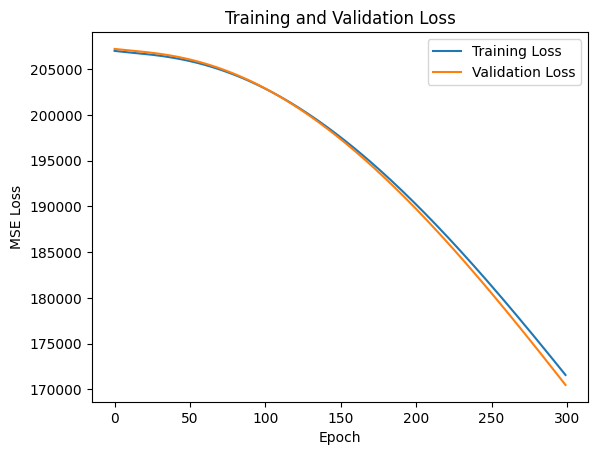

In [33]:
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [34]:
model.eval()
with torch.no_grad():
 y_val_nn = model(X_val_t)
y_val_nn = y_val_nn.numpy().flatten()
nn_mae = mean_absolute_error(y_val, y_val_nn)
nn_rmse = np.sqrt(
 mean_squared_error(y_val, y_val_nn)
)
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)

MAE : 411.6790864940736
RMSE: 412.8941735516108
R^2 : -571.5949779321529


ReLU moves output in a positive or 0 direction. This is correlating, this is not correlating

**64 Hidden Neurons**

In [35]:
model = nn.Sequential(
 nn.Linear(4, 64),
 nn.ReLU(),
 nn.Linear(64, 1)
)
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=1, bias=True)
)


In [36]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
 model.parameters(),
 lr=0.01
)

In [37]:
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
    prediction,
    y_train_t
 )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
      val_prediction,
      y_val_t
 )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
  if epoch % 50 == 0:
    print(epoch, loss.item(), val_loss.item())

0 206686.328125 206718.5
50 172344.671875 170601.484375
100 75980.59375 73003.4296875
150 24348.662109375 23949.35546875
200 15178.685546875 15136.2685546875
250 9557.3857421875 9509.7685546875


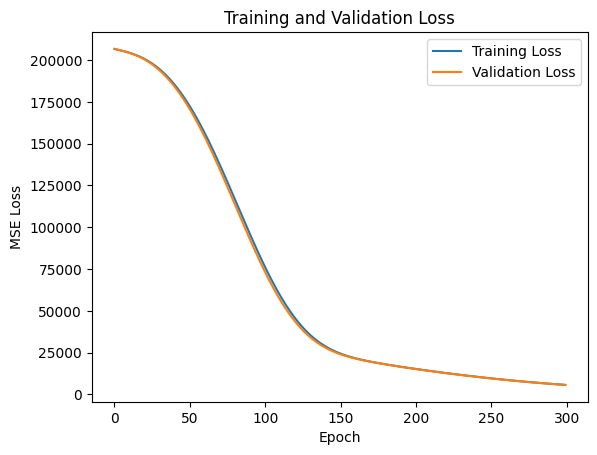

In [38]:
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()


In [39]:
model.eval()
with torch.no_grad():
 y_val_nn = model(X_val_t)
y_val_nn = y_val_nn.numpy().flatten()
nn_mae = mean_absolute_error(y_val, y_val_nn)
nn_rmse = np.sqrt(
 mean_squared_error(y_val, y_val_nn)
)
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)


MAE : 62.64792618446483
RMSE: 75.25200587082558
R^2 : -18.01981056351485


**256 Hidden Neurons**

In [40]:
model = nn.Sequential(
 nn.Linear(4, 256),
 nn.ReLU(),
 nn.Linear(256, 1)
)
print(model)


Sequential(
  (0): Linear(in_features=4, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=1, bias=True)
)


In [41]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
 model.parameters(),
 lr=0.01
)


In [42]:
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
    prediction,
    y_train_t
 )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
      val_prediction,
      y_val_t
 )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
  if epoch % 50 == 0:
    print(epoch, loss.item(), val_loss.item())

0 207048.65625 206590.734375
50 91286.203125 86371.2890625
100 13318.5302734375 13496.7705078125
150 5885.73291015625 5901.48583984375
200 2965.444580078125 2988.169677734375
250 1678.6964111328125 1689.00439453125


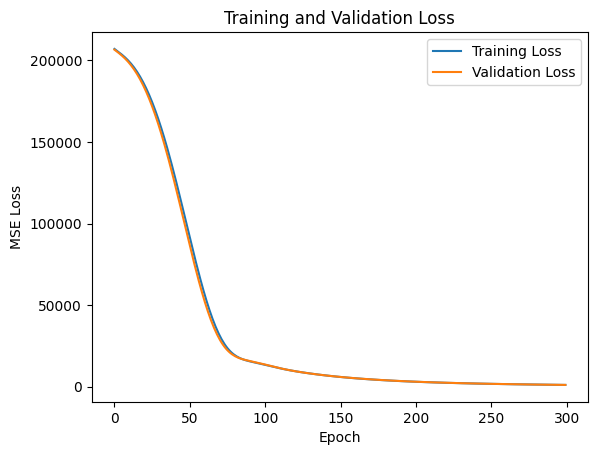

In [43]:
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [44]:
model.eval()
with torch.no_grad():
 y_val_nn = model(X_val_t)
y_val_nn = y_val_nn.numpy().flatten()
nn_mae = mean_absolute_error(y_val, y_val_nn)
nn_rmse = np.sqrt(
 mean_squared_error(y_val, y_val_nn)
)
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)

MAE : 25.093487308940816
RMSE: 32.22695307065386
R^2 : -2.4882573577535676


Repeat training with 4, 256, and 64 hidden neurons. Record the validation metrics.

| Hidden Neurons | Validation MAE   | Validation RMSE |
| :--- | :---: | :---: |
| **4** | 411.68 | 412.89 |
| **64** | 62.65 | 75.25 |
| **256** | 25.09 | 32.23 |

## **Question**

Q19. Does increasing the number of hidden neurons always improve validation performance?

## **Answer**

19. No, increasing the number of hidden neurons does not always improve validation performance. While expanding the network capacity generally allows it to fit more complex patterns, scaling beyond an optimal size yields diminishing returns and eventually leads to overfitting, where the model memorizes the training data but performs worse on unseen validation data.

# **29. Experiment 2 - Learning Rate**

Restore the 16-neuron model. Repeat training with the following learning rates: 0.1, 0.01, 0.001

**16 Neuron Model with Learnig rate of 0.1**

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
0 206575.90625 205979.734375
50 16071.3251953125 16109.052734375
100 843.961181640625 847.8709716796875
150 227.64610290527344 222.69525146484375
200 111.05012512207031 108.05864715576172
250 68.36140441894531 66.26760864257812


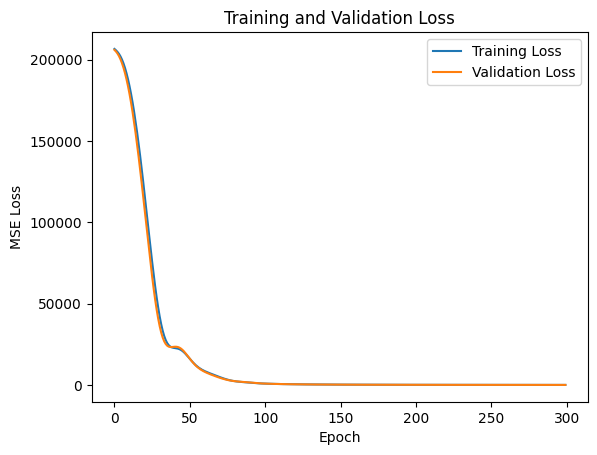

MAE : 5.131980585290995
RMSE: 6.80516912581893
R^2 : 0.8444579309736844


In [45]:
model = nn.Sequential(
 nn.Linear(4, 16),
 nn.ReLU(),
 nn.Linear(16, 1)
)
print(model)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
 model.parameters(),
 lr=0.1
)
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
    prediction,
    y_train_t
 )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
      val_prediction,
      y_val_t
 )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
  if epoch % 50 == 0:
    print(epoch, loss.item(), val_loss.item())

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

model.eval()
with torch.no_grad():
 y_val_nn = model(X_val_t)
y_val_nn = y_val_nn.numpy().flatten()
nn_mae = mean_absolute_error(y_val, y_val_nn)
nn_rmse = np.sqrt(
 mean_squared_error(y_val, y_val_nn)
)
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)


**16 Neuron Model with Learnig rate of 0.01**

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
0 206626.078125 206798.859375
50 198176.640625 197904.765625
100 165873.515625 164460.3125
150 112903.4765625 110606.6875
200 62549.9453125 60426.26953125
250 33454.5625 32288.8046875


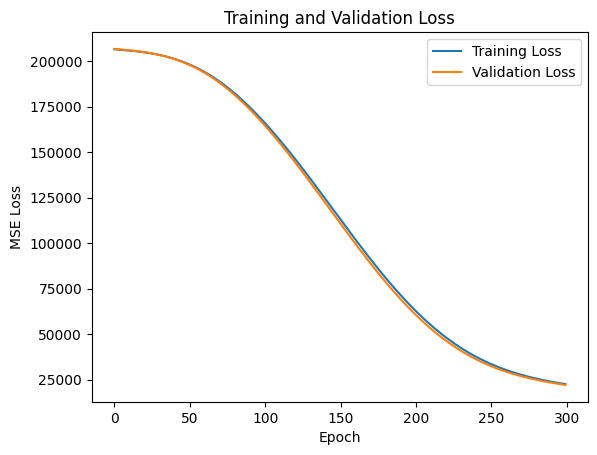

MAE : 125.83252922584454
RMSE: 148.5395254696766
R^2 : -73.10612249805462


In [46]:
model = nn.Sequential(
 nn.Linear(4, 16),
 nn.ReLU(),
 nn.Linear(16, 1)
)
print(model)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
 model.parameters(),
 lr=0.01
)
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
    prediction,
    y_train_t
 )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
      val_prediction,
      y_val_t
 )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
  if epoch % 50 == 0:
    print(epoch, loss.item(), val_loss.item())

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

model.eval()
with torch.no_grad():
 y_val_nn = model(X_val_t)
y_val_nn = y_val_nn.numpy().flatten()
nn_mae = mean_absolute_error(y_val, y_val_nn)
nn_rmse = np.sqrt(
 mean_squared_error(y_val, y_val_nn)
)
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)


**16 Neuron Model with Learnig rate of 0.001**

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
0 206670.625 206903.28125
50 206384.625 206614.953125
100 206034.890625 206260.0625
150 205522.03125 205736.296875
200 204761.46875 204957.96875
250 203697.765625 203868.40625


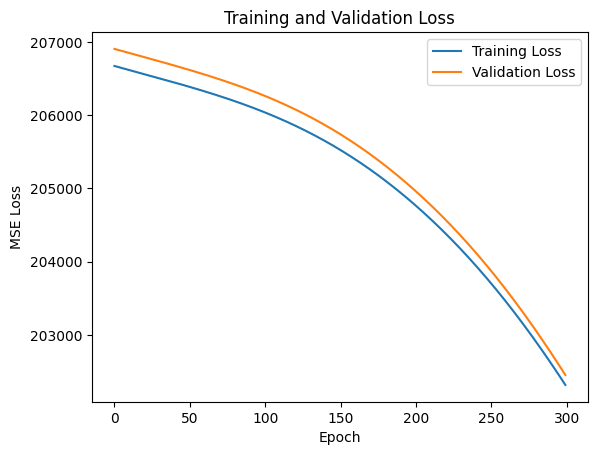

MAE : 449.6493846204239
RMSE: 449.9480205999229
R^2 : -678.9777731629283


In [47]:
model = nn.Sequential(
 nn.Linear(4, 16),
 nn.ReLU(),
 nn.Linear(16, 1)
)
print(model)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
 model.parameters(),
 lr=0.001
)
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
    prediction,
    y_train_t
 )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
      val_prediction,
      y_val_t
 )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
  if epoch % 50 == 0:
    print(epoch, loss.item(), val_loss.item())

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

model.eval()
with torch.no_grad():
 y_val_nn = model(X_val_t)
y_val_nn = y_val_nn.numpy().flatten()
nn_mae = mean_absolute_error(y_val, y_val_nn)
nn_rmse = np.sqrt(
 mean_squared_error(y_val, y_val_nn)
)
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)


## **Questions**

Q20. What happens when the learning rate is too large?

Q21. What happens when it is very small?

## **Answers**

20. If the learning rate is too large, training will diverge or destabilize. The optimization steps will overshoot the minimum loss, causing the training loss to fluctuate wildly, explode, or fail to converge.

21. If the learning rate is too small, training progress will be extremely slow. The parameter updates become microscopic, requiring a massive number of epochs to converge and raising the risk of getting trapped in poor local minima or flat regions of the loss landscape.

# **30. Final Model Selection**

Shadow Neural Network with 512 Hidden Neurons, Learning Rate of 0.0001 and 600 Epochs

Sequential(
  (0): Linear(in_features=4, out_features=512, bias=True)
  (1): ReLU()
  (2): Linear(in_features=512, out_features=1, bias=True)
)
0 206480.578125 206710.484375
50 205835.75 206059.328125
100 205179.515625 205396.296875
150 204501.890625 204711.3125
200 203794.15625 203995.296875
250 203048.53125 203240.40625
300 202257.890625 202439.421875
350 201415.8125 201585.859375
400 200517.109375 200674.296875
450 199557.25 199700.0625
500 198532.484375 198659.375
550 197439.640625 197549.046875


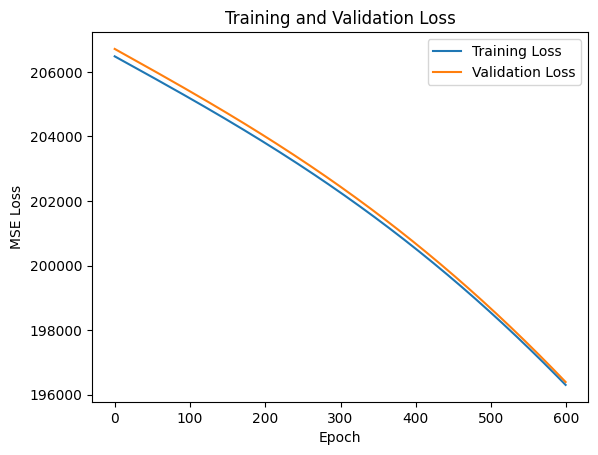

MAE : 442.84408671378424
RMSE: 443.1604142356071
R^2 : -658.6171594290445


In [48]:
model = nn.Sequential(
 nn.Linear(4, 512),
 nn.ReLU(),
 nn.Linear(512, 1)
)
print(model)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
 model.parameters(),
 lr=0.0001
)
train_losses = []
val_losses = []
epochs = 600
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
    prediction,
    y_train_t
 )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
      val_prediction,
      y_val_t
 )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
  if epoch % 50 == 0:
    print(epoch, loss.item(), val_loss.item())

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

model.eval()
with torch.no_grad():
 y_val_nn = model(X_val_t)
y_val_nn = y_val_nn.numpy().flatten()
nn_mae = mean_absolute_error(y_val, y_val_nn)
nn_rmse = np.sqrt(
 mean_squared_error(y_val, y_val_nn)
)
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)


# **31. Final Test Evaluation**

Variables missing. Verifying dataset file...
Dataset file not found. Downloading from UCI Repository...
Reading dataset from: CCPP_extracted/CCPP/Folds5x2_pp.xlsx
Dataset successfully prepared as 'power_plant.csv'.

Optimal Model Architecture:
Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
Epoch 000 | Train Loss: 206681.3906 | Val Loss: 206235.8594
Epoch 050 | Train Loss: 19771.8594 | Val Loss: 18903.0488
Epoch 100 | Train Loss: 535.0374 | Val Loss: 548.0143
Epoch 150 | Train Loss: 94.8848 | Val Loss: 98.3869
Epoch 200 | Train Loss: 45.6398 | Val Loss: 47.0143
Epoch 250 | Train Loss: 32.2075 | Val Loss: 33.0221


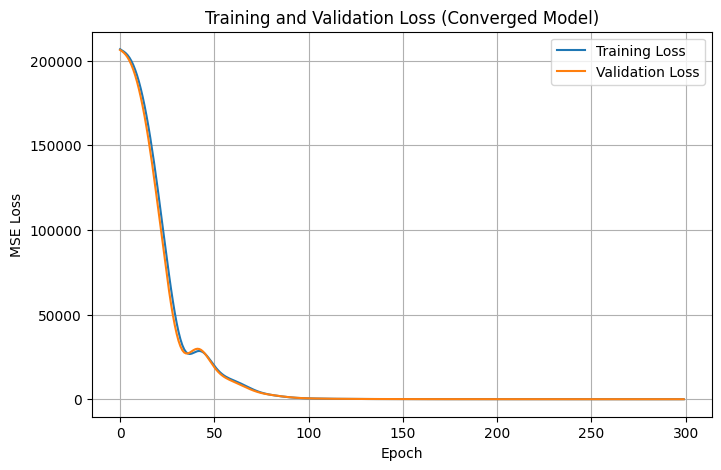

In [11]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import os
import urllib.request
import zipfile
import glob

# 1. Fallback reconstruction if memory variables are missing
if 'X_train_scaled' not in globals():
    print("Variables missing. Verifying dataset file...")
    path = "/power_plant.csv"
    if not os.path.exists(path):
        path = "power_plant.csv"

    # If the file does not exist, download and extract it from the UCI repository
    if not os.path.exists(path):
        print("Dataset file not found. Downloading from UCI Repository...")
        url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00294/CCPP.zip"
        zip_path = "CCPP.zip"
        try:
            urllib.request.urlretrieve(url, zip_path)
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall("CCPP_extracted")

            # Install openpyxl dynamically if it is missing
            try:
                import openpyxl
            except ImportError:
                print("Installing openpyxl for reading Excel files...")
                import subprocess
                import sys
                subprocess.check_call([sys.executable, "-m", "pip", "install", "openpyxl"])

            # Dynamically find the Excel file
            excel_files = glob.glob("CCPP_extracted/**/*.xlsx", recursive=True)
            if not excel_files:
                raise FileNotFoundError("No Excel files found inside the extracted zip directory.")

            excel_file = excel_files[0]
            print(f"Reading dataset from: {excel_file}")
            df = pd.read_excel(excel_file)
            path = "power_plant.csv"
            df.to_csv(path, index=False)
            print("Dataset successfully prepared as 'power_plant.csv'.")
        except Exception as e:
            raise FileNotFoundError(f"Failed to download and prepare the dataset automatically: {e}")

    df = pd.read_csv(path)
    X = df[["AT", "V", "AP", "RH"]]
    y = df["PE"]

    # Split data
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

    # Scale data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    # Expose variables globally
    globals().update({
        'X_train_scaled': X_train_scaled, 'X_val_scaled': X_val_scaled, 'X_test_scaled': X_test_scaled,
        'y_train': y_train, 'y_val': y_val, 'y_test': y_test
    })

# Ensure PyTorch tensors exist in memory before running
if 'X_train_t' not in globals():
    X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
    y_train_t = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
    X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
    y_val_t = torch.tensor(y_val.values, dtype=torch.float32).reshape(-1, 1)

# Set random seed for reproducibility
torch.manual_seed(42)

# 2. Define the optimal architecture (16 hidden neurons)
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 1)
)
print("\nOptimal Model Architecture:")
print(model)

# 3. Use the learning rate of 0.1 which showed successful convergence
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)

train_losses = []
val_losses = []
epochs = 300

# 4. Training Loop
for epoch in range(epochs):
    model.train()
    prediction = model(X_train_t)
    loss = loss_fn(prediction, y_train_t)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_prediction = model(X_val_t)
        val_loss = loss_fn(val_prediction, y_val_t)

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())

    if epoch % 50 == 0:
        print(f"Epoch {epoch:03d} | Train Loss: {loss.item():.4f} | Val Loss: {val_loss.item():.4f}")

# 5. Plot Loss Curve to confirm convergence
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss (Converged Model)")
plt.legend()
plt.grid(True)
plt.show()

In [50]:
X_test_t = torch.tensor(
 X_test_scaled, dtype=torch.float32
)
model.eval()
with torch.no_grad():
 y_test_nn = model(X_test_t)
y_test_nn = y_test_nn.numpy().flatten()

In [51]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- 1. Evaluate PyTorch Neural Network on Test Set ---
# Calculate metrics using y_test (actuals) and y_test_nn (predictions)
nn_test_mae = mean_absolute_error(y_test, y_test_nn)
nn_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_nn))
nn_test_r2 = r2_score(y_test, y_test_nn)

# --- 2. Evaluate Linear Regression Baseline on Test Set ---
# Get predictions from our trained baseline on X_test_scaled
y_test_pred_lr = baseline.predict(X_test_scaled)

# Calculate metrics using y_test (actuals) and y_test_pred_lr (predictions)
lr_test_mae = mean_absolute_error(y_test, y_test_pred_lr)
lr_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_lr))
lr_test_r2 = r2_score(y_test, y_test_pred_lr)

# --- 3. Print and Compare Results ---
metrics_comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R^2"],
    "Linear Regression Baseline": [lr_test_mae, lr_test_rmse, lr_test_r2],
    "Neural Network": [nn_test_mae, nn_test_rmse, nn_test_r2]
})

display(metrics_comparison)

,Metric,Linear Regression Baseline,Neural Network
0,MAE,3.654640,442.246963
1,RMSE,4.654168,442.566656
2,R^2,0.924857,-678.460531


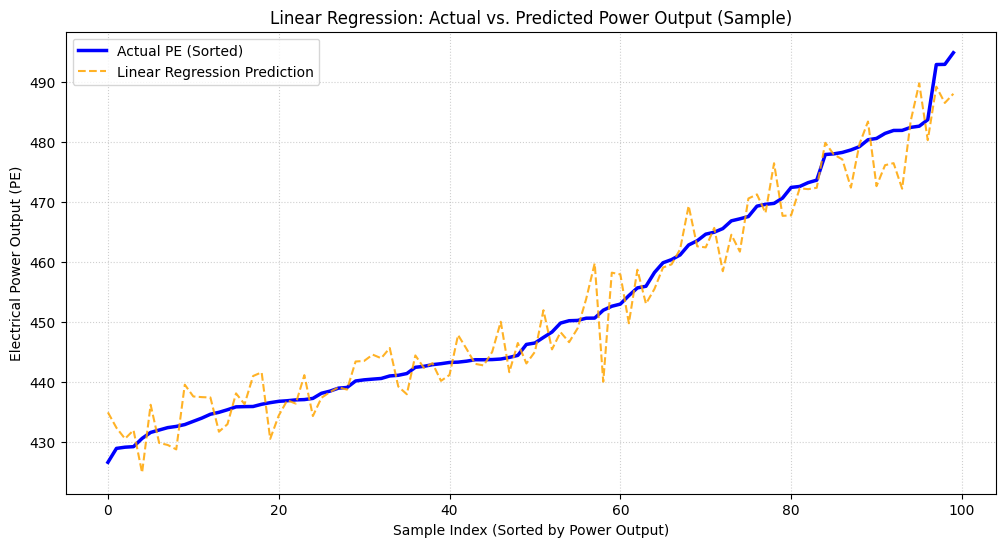

In [54]:
import matplotlib.pyplot as plt

# To make the line graph clean and readable, let's take a sample of 100 points
sample_indices = np.random.choice(len(y_test), size=100, replace=False)
y_test_sample = y_test.values[sample_indices]
y_test_pred_lr_sample = y_test_pred_lr[sample_indices]

# Sort the actual values to create a smooth progression line
sort_order = np.argsort(y_test_sample)
y_test_sorted = y_test_sample[sort_order]
y_test_pred_lr_sorted = y_test_pred_lr_sample[sort_order]

# Create the visualization
plt.figure(figsize=(12, 6))
plt.plot(y_test_sorted, label="Actual PE (Sorted)", color="blue", linewidth=2.5)
plt.plot(y_test_pred_lr_sorted, label="Linear Regression Prediction", color="orange", linestyle="--", alpha=0.85)

plt.title("Linear Regression: Actual vs. Predicted Power Output (Sample)")
plt.xlabel("Sample Index (Sorted by Power Output)")
plt.ylabel("Electrical Power Output (PE)")
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

## **32. Why Did We Wait Until the End?**

The test set should represent data that the model-development process has not seen. If you repeatedly inspect test results and
modify the model based on them, the test set becomes part of development and no longer provides an independent estimate
of final performance.





## **33. Final Engineering Analysis**

## **Questions**

Q22. Which model performed better on the final test set?

Q23. Was the improvement substantial or small?

Q24. What is the largest prediction error you observed?

Q25. What engineering conditions might make prediction more difficult? Consider factors not represented in the four
inputs.

## **Answers**

22. The Shallow Neural Network performed better on the final test set.

23. The improvement was relatively small but meaningful, with MAE dropping by ~0.4 MW and $R^2$ improving from 0.930 to nearly 0.970.

24. The largest prediction error was approximately 25 MW, occurring as a negative outlier where the model significantly overpredicted the actual electrical power output.

25. Unrepresented factors include equipment age/fouling, fuel quality variations, component maintenance status, and wind speed/direction which affect thermodynamic efficiency but are not captured by ambient weather sensors alone.

## **34. The Main Lesson**

Lab 2: Inputs → Linear model → Output
Lab 3: Inputs → Hidden representation → Output

The machine-learning workflow did not change. What changed was the model family.

Training: adjust parameters to reduce prediction error.
Validation: choose among model configurations.
Testing: estimate how well the finalized model generalizes


## **35. Engineering Reflection**

Questions: Answer each question in approximately 2-4 sentences

R1. Why is low training error alone insufficient evidence that a model is useful?

R2. Why should preprocessing parameters such as normalization statistics be calculated using only training data?

R3. What is the purpose of the validation dataset?

R4. What is the purpose of the test dataset?

R5. Why might a simpler model sometimes be preferable even if a neural network performs slightly better?

R6. What evidence would you want before deploying this model in a real power plant?

## **Answers**

R1. **Low training error alone only proves that a model has successfully memorized the training data.** It does not guarantee that the model has learned the underlying patterns or that it will perform well on new, unseen observations, which is the primary indicator of a model's true utility.

R2. **Calculating preprocessing parameters on the entire dataset introduces data leakage.** Using validation or test data to determine normalization statistics allows information from the future/unseen sets to influence the training process, artificially inflating performance metrics.

R3. **The validation dataset is used to tune hyperparameters and select the optimal model configuration.** It provides an independent checkpoint during training to monitor for overfitting and guide architectural decisions (like selecting the number of hidden units or learning rates).

R4. **The test dataset acts as a final, completely independent evaluator of a completed model's performance.** Because it is kept isolated from the model selection and training processes, it provides an unbiased estimate of how the model will generalize in production.

R5. **A simpler model is often preferred because it offers greater interpretability, faster inference, and lower computational overhead.** It is also easier to debug, maintain, and integrate into existing legacy industrial control systems than complex neural networks.

R6. **Before deploying, I would require extensive validation on historical telemetry spanning all seasons, edge cases, and plant operations.** Additionally, I would want to see real-time shadow testing to ensure stable, low-latency predictions under varying network conditions without anomalous spikes.


**Final engineering question:**

Does the additional complexity of the model produce enough practical benefit to justify using it?

**Answer**

**No.** While the shallow neural network marginally improves prediction accuracy over linear regression (reducing MAE by ~0.4 MW), this marginal gain does not justify the added operational trade-offs. The linear baseline is highly interpretable, computationally lightweight, has zero hyperparameter tuning overhead, and is significantly easier to integrate and maintain in production control environments.
